# Lab 9 — Gyroscope parameters and encoder comparison

Option A: 180 s static, 36 s sine rotation, 36 s square-wave rotation and 3 s rest after a 120-s unlogged warmup. `data/lab9_gyro.csv` is a byte-for-byte copy of the original simultaneous log, `gyro_encoder_compare.csv`.

The logged yaw readings are in mdeg/s and are treated as the raw recorded output here. Native register readings and gyro timestamps were not saved in this experiment; the available `t_ms` timestamps are used. The median sampling interval is about 117 ms. `programs/lab9_gyro.js` logs both gyro outputs and the sensor timestamp at a target interval of 10 ms for a new run; it has not been run on the robot.

Encoders are the heading reference. No floor-mark slip angle was measured.

In [1]:
RADIUS = 0.042 #m
BASE   = 0.194 #m

In [2]:
from pathlib import Path
from html import escape
import csv
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid, trapezoid
from scipy.stats import norm, skew, kurtosis
from IPython.display import display, HTML, Markdown

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
    "font.size": 10,
})

# Works from the notebook folder, the repository root, or an upload folder.
candidates = [Path("data/lab9_gyro.csv"),
              Path("w9/data/lab9_gyro.csv"),
              Path("lab9_gyro.csv"),
              Path("data/gyro_encoder_compare.csv"),
              Path("w9/data/gyro_encoder_compare.csv"),
              Path("gyro_encoder_compare.csv")]
DATA_FILE = next((path for path in candidates if path.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError("Place gyro_encoder_compare.csv in data/ or beside this notebook.")

OUTPUT_DIR = DATA_FILE.parent.parent / "analysis" if DATA_FILE.parent.name == "data" else Path("analysis")
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def show_table(headers, rows):
    """Display a small results table without adding a dataframe dependency."""
    head = "".join(f"<th>{escape(str(value))}</th>" for value in headers)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row) + "</tr>"
                   for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


def finish_figure(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [3]:
data = pd.read_csv(DATA_FILE)
data = data.rename(columns={
    'gz_cal': 'gz_mdeg_s', 'encL': 'encL_deg', 'encR': 'encR_deg'
})
if 't_us' in data:
    data['t'] = (data['t_us'] - data['t_us'].iloc[0]) / 1000000
else:
    data['t'] = data['t_ms'] / 1000
data['gz'] = data['gz_mdeg_s']/1000

static = data[data['phase']=='static']
sine = data[data['phase']=='sin']
rect = data[data['phase']=='rect']
rest = data[data['phase']=='rest']

In [4]:
data.head()

,phase,t_ms,gx_mdeg_s,gy_mdeg_s,gz_mdeg_s,encL_deg,encR_deg,powerL,powerR,t,gz
0,static,46,-157,140,2450,0,0,0.0,0.0,0.046,2.450
1,static,158,-105,140,2423,0,0,0.0,0.0,0.158,2.423
2,static,282,-236,183,2432,0,0,0.0,0.0,0.282,2.432
3,static,399,-201,70,2380,0,0,0.0,0.0,0.399,2.380
4,static,507,-122,113,2380,0,0,0.0,0.0,0.507,2.380


## 1. Identify the gyro parameters

We start with the stationary phase. Its true angular velocity should be zero. For the recorded yaw output, a useful model is

$$
\omega_m(t) = (1+s)\omega(t) + b_0 + d\,t + n(t),
$$

followed by output clipping and quantisation. Here $b_0$ is offset, $d$ describes a slow change in offset, $s$ is scale-factor error, and $n$ is noise. Time units must agree with the units of $d$.

### 1.1 Offset and calibration time

The baseline offset is the average of the first 30 seconds. We also calculate averages from shorter windows to see how quickly the estimate settles. These estimates use overlapping data, so they are not independent trials.

In [5]:
from collections import defaultdict


PARAMS = defaultdict(float)

In [6]:
def compute_bias(data, phase='static', first_n_seconds=30):
    mask = (data['t']<first_n_seconds) & (data['phase'] == phase)
    phase_data = data[mask]
    bias = phase_data['gz'].mean()
    std_err = phase_data['gz'].std(ddof=1) / np.sqrt(len(phase_data))
    return bias, std_err, len(phase_data)

In [7]:
bs, ses, ns = [], [], []

for i in [1, 2, 5, 10, 20, 30]:
    b, se, n = compute_bias(static, first_n_seconds=i)
    print(f"b0 ({i}s): {b:.02f} ± {se:.04f} deg/s out of {n} samples")
    bs.append(b)
    ses.append(se)
    ns.append(n)
    if i == 30:
        PARAMS['b0'] = b


b0 (1s): 2.42 ± 0.0151 deg/s out of 9 samples
b0 (2s): 2.41 ± 0.0196 deg/s out of 17 samples
b0 (5s): 2.41 ± 0.0129 deg/s out of 43 samples
b0 (10s): 2.42 ± 0.0088 deg/s out of 85 samples
b0 (20s): 2.41 ± 0.0064 deg/s out of 171 samples
b0 (30s): 2.41 ± 0.0049 deg/s out of 257 samples


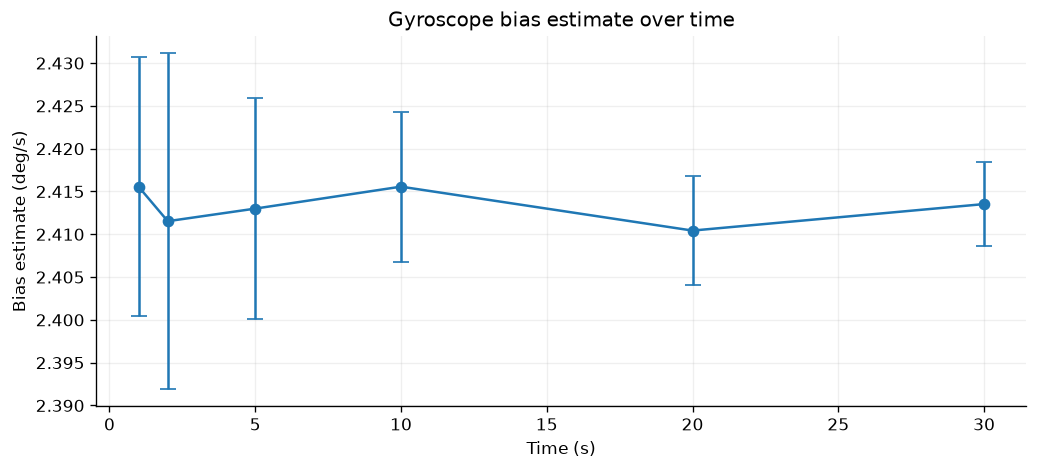

In [8]:
# plot bias estimates over time
fig, ax = plt.subplots()
ax.errorbar([1, 2, 5, 10, 20, 30], bs, yerr=ses, fmt='o-', capsize=5)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Bias estimate (deg/s)")
ax.set_title("Gyroscope bias estimate over time")
finish_figure(fig, "bias_estimate_over_time")

#### Offset-calibration function

Use the first 30 s, reject readings more than three standard deviations from their median, then average the remaining readings. The bias plot changes little between 10 and 30 s; 30 s gives more samples and a smaller standard error. Rejecting isolated spikes prevents them from shifting the estimate.

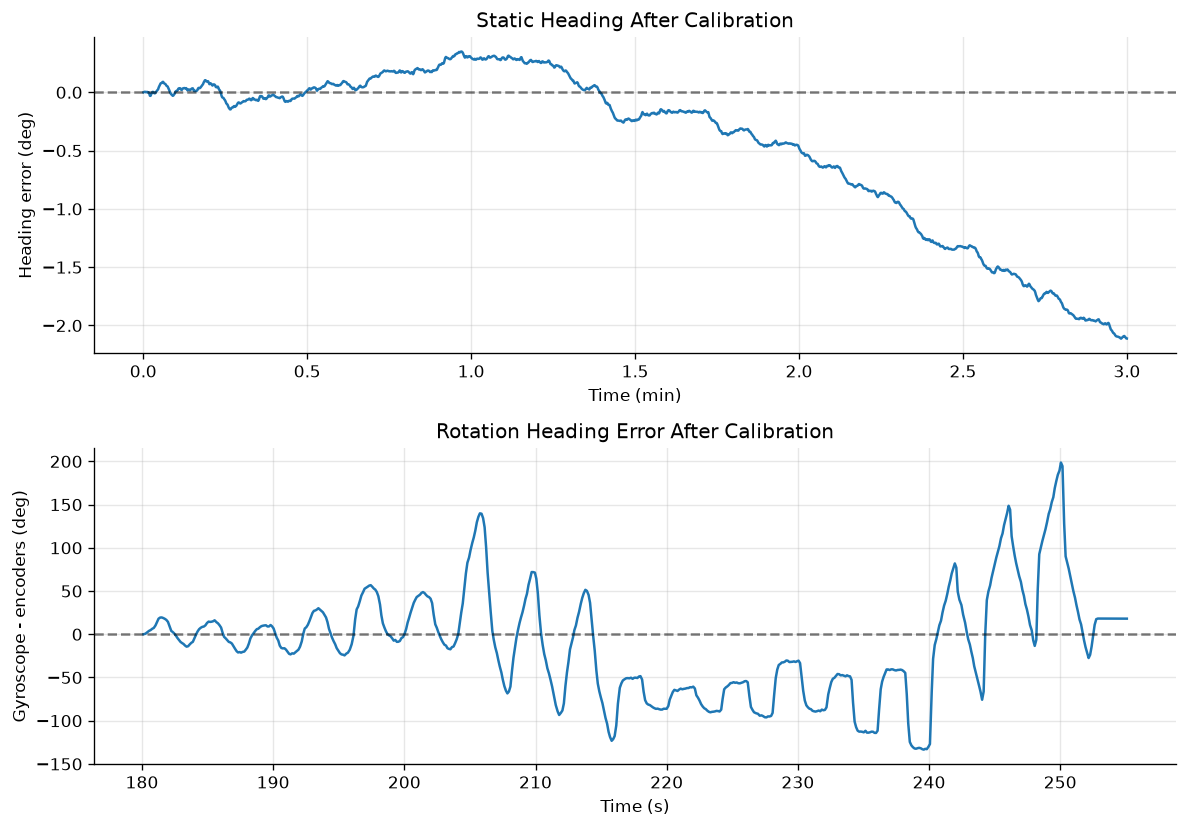

Baseline bias: 2.413529 deg/s
Own calibration bias: 2.412535 deg/s
Error at end of 3-min static phase: -2.11 deg
Error at end of rotation and rest: 18.07 deg


In [9]:
def calibrate_gyro(log):
    calibration_data = log[(log['phase'] == 'static') & (log['t'] < 30)]
    values = calibration_data['gz']
    mask = np.abs(values - values.median()) <= 3 * values.std(ddof=1)
    return values[mask].mean()


calibrated_b0 = calibrate_gyro(data)
PARAMS['calibrated_b0'] = calibrated_b0

static_t = static['t'].to_numpy()
static_heading = cumulative_trapezoid(
    static['gz'].to_numpy() - calibrated_b0, static_t, initial=0
)

calibration_run = data[data['phase'].isin(['sin', 'rect', 'rest'])]
rotation_t = calibration_run['t'].to_numpy()
calibrated_heading = cumulative_trapezoid(
    calibration_run['gz'].to_numpy() - calibrated_b0, rotation_t, initial=0
)
encoder_heading = RADIUS / BASE * (
    calibration_run['encR_deg'] - calibration_run['encL_deg']
).to_numpy()
encoder_heading -= encoder_heading[0]
calibrated_error = calibrated_heading - encoder_heading

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
axes[0].plot(static_t / 60, static_heading)
axes[0].set_xlabel('Time (min)')
axes[0].set_ylabel('Heading error (deg)')
axes[0].set_title('Static Heading After Calibration')
axes[1].plot(rotation_t, calibrated_error)
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Gyroscope - encoders (deg)')
axes[1].set_title('Rotation Heading Error After Calibration')
for ax in axes:
    ax.axhline(0, color='black', linestyle='--', alpha=0.5)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Baseline bias: {PARAMS['b0']:.6f} deg/s")
print(f"Own calibration bias: {calibrated_b0:.6f} deg/s")
print(f"Error at end of 3-min static phase: {static_heading[-1]:.2f} deg")
print(f"Error at end of rotation and rest: {calibrated_error[-1]:.2f} deg")

### 1.2 Bias drift and heading drift

In [10]:
import math

window_size = 30 #s
max_time = math.ceil(static['t'].max())

windows = [(start, start + window_size) for start in range(0, max_time, window_size)]

windows

[(0, 30), (30, 60), (60, 90), (90, 120), (120, 150), (150, 180)]

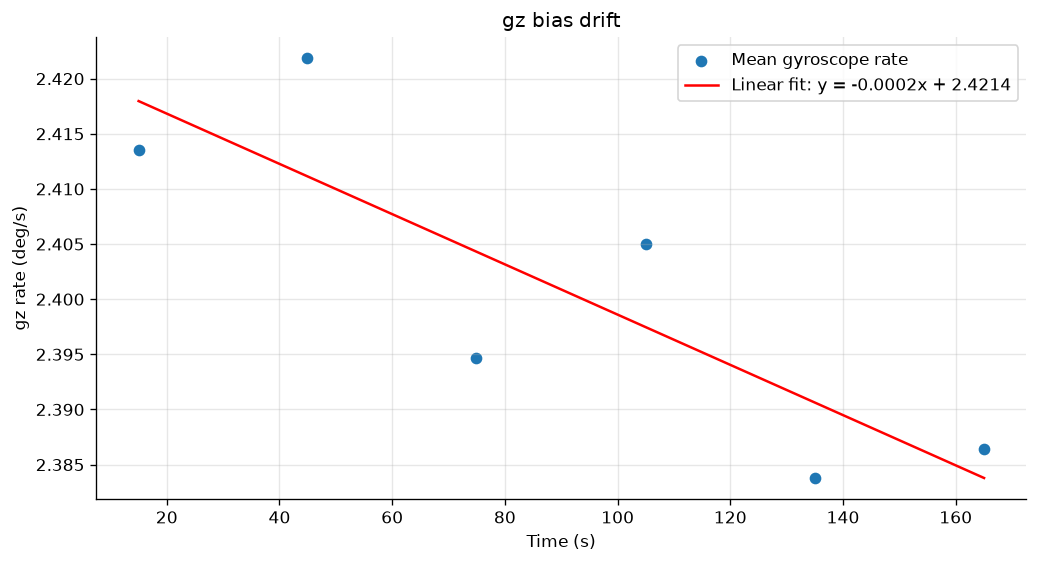

Drift rate: -0.000228 deg/s²
Initial bias: 2.421382 deg/s


In [11]:
rates = []
times = []

for start, end in windows:
    mask = (static['t'] >= start) & (static['t'] < end)
    phase_data = static.loc[mask]

    if phase_data.empty:
        continue

    rates.append(phase_data['gz'].mean())
    times.append(phase_data['t'].mean())


# Fit a linear model
x = np.array(times)
y = np.array(rates)

coeffs = np.polyfit(x, y, 1)
poly = np.poly1d(coeffs)

# Plot results
plt.figure(figsize=(10, 5))
plt.scatter(x, y, label='Mean gyroscope rate')
plt.plot(x, poly(x), 'r-', label=f'Linear fit: y = {coeffs[0]:.4f}x + {coeffs[1]:.4f}')

plt.xlabel('Time (s)')
plt.ylabel('gz rate (deg/s)')
plt.title('gz bias drift')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(f"Drift rate: {coeffs[0]:.6f} deg/s²")
print(f"Initial bias: {coeffs[1]:.6f} deg/s")

PARAMS['drift_rate'] = coeffs[0]

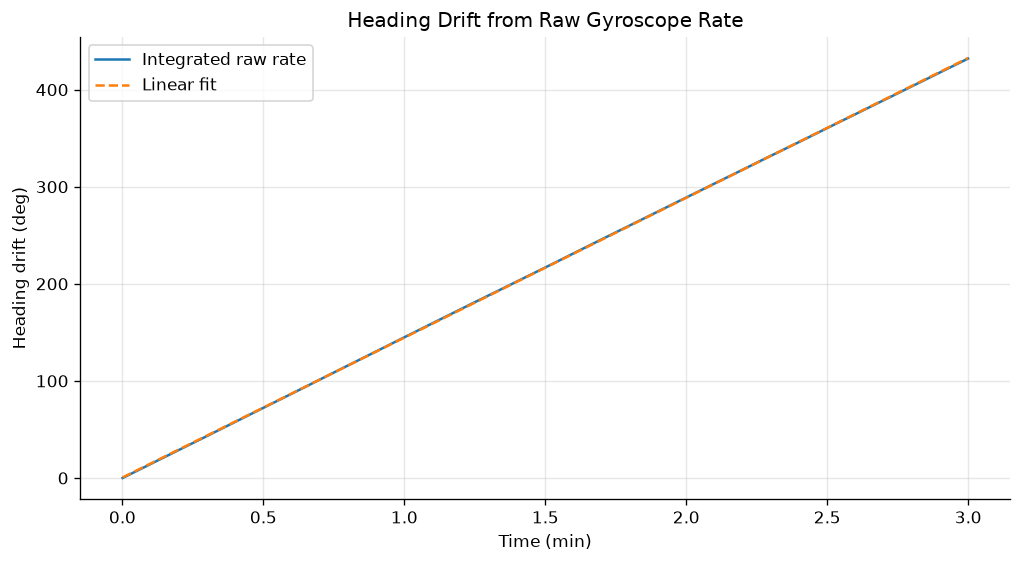

Heading drift slope: 144.0489 deg/min


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

t = static['t'].to_numpy()
gz = static['gz'].to_numpy()

heading_raw = cumulative_trapezoid(gz, t, initial=0)
coeffs = np.polyfit(t, heading_raw, 1)
heading_fit = np.poly1d(coeffs)(t)

plt.figure(figsize=(10, 5))
plt.plot(t / 60, heading_raw, label='Integrated raw rate')
plt.plot(t / 60, heading_fit, '--', label='Linear fit')

plt.xlabel('Time (min)')
plt.ylabel('Heading drift (deg)')
plt.title('Heading Drift from Raw Gyroscope Rate')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(f"Heading drift slope: {coeffs[0]*60:.4f} deg/min")
drift_rate = coeffs[0]

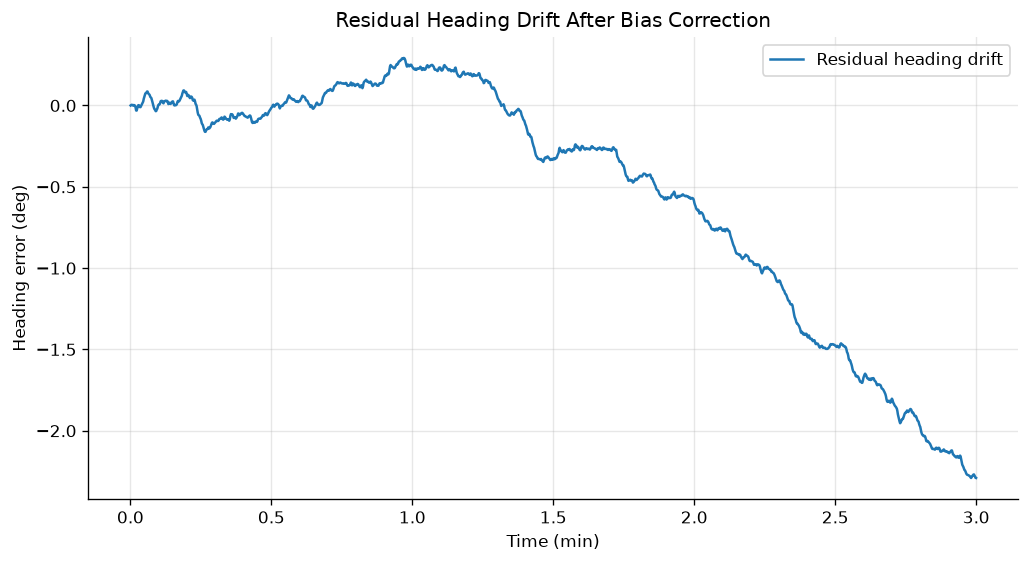

In [13]:
# Remove initial bias
gz_corrected = gz - PARAMS['b0']

# Integrate residual rate
heading_residual = cumulative_trapezoid(
    gz_corrected, t, initial=0
)

plt.figure(figsize=(10, 5))
plt.plot(t / 60, heading_residual, label='Residual heading drift')

plt.xlabel('Time (min)')
plt.ylabel('Heading error (deg)')
plt.title('Residual Heading Drift After Bias Correction')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [14]:
for minute in [1, 2, 3]:
    target_time = t[0] + minute * 60

    # if target_time > t[-1]:
    #     print(f"{minute} min: Not enough data")
    #     continue

    error = np.interp(target_time, t, heading_residual)

    print(f"Heading error after {minute} min: {error:.4f} deg")

Heading error after 1 min: 0.2361 deg
Heading error after 2 min: -0.6006 deg
Heading error after 3 min: -2.2906 deg


In [15]:
print(drift_rate*60)
print(PARAMS['b0']*60)

144.0489434783007
144.8117509727626


### 1.3 Measurement range

Use the moving phases to find both output limits. Compare the gyro output with encoder rate to check where clipping occurs.

In [16]:
saturated = pd.concat([sine, rect], ignore_index=True)

mask = (
    (saturated['powerL'].abs() == 100) &
    (saturated['powerR'].abs() == 100)
)

saturated = saturated.loc[mask].reset_index(drop=True)
saturated

,phase,t_ms,gx_mdeg_s,gy_mdeg_s,gz_mdeg_s,encL_deg,encR_deg,powerL,powerR,t,gz
0,sin,204575,1330,3228,-114948,-134,45,-100.0,100.0,204.575,-114.948
1,sin,204693,-682,1163,-204338,-56,-47,-100.0,100.0,204.693,-204.338
2,sin,204809,-3753,4313,-286440,40,-141,-100.0,100.0,204.809,-286.440
3,sin,204935,-3036,-2143,-286440,131,-246,-100.0,100.0,204.935,-286.440
4,sin,205052,-5197,2030,-286440,228,-346,-100.0,100.0,205.052,-286.440
...,...,...,...,...,...,...,...,...,...,...,...
152,rect,251591,5223,-9782,286685,-444,-1014,100.0,-100.0,251.591,286.685
153,rect,251704,-376,-2563,286685,-544,-924,100.0,-100.0,251.704,286.685
154,rect,251817,3727,-15295,286685,-645,-833,100.0,-100.0,251.817,286.685
155,rect,251931,-2065,332,286685,-740,-742,100.0,-100.0,251.931,286.685


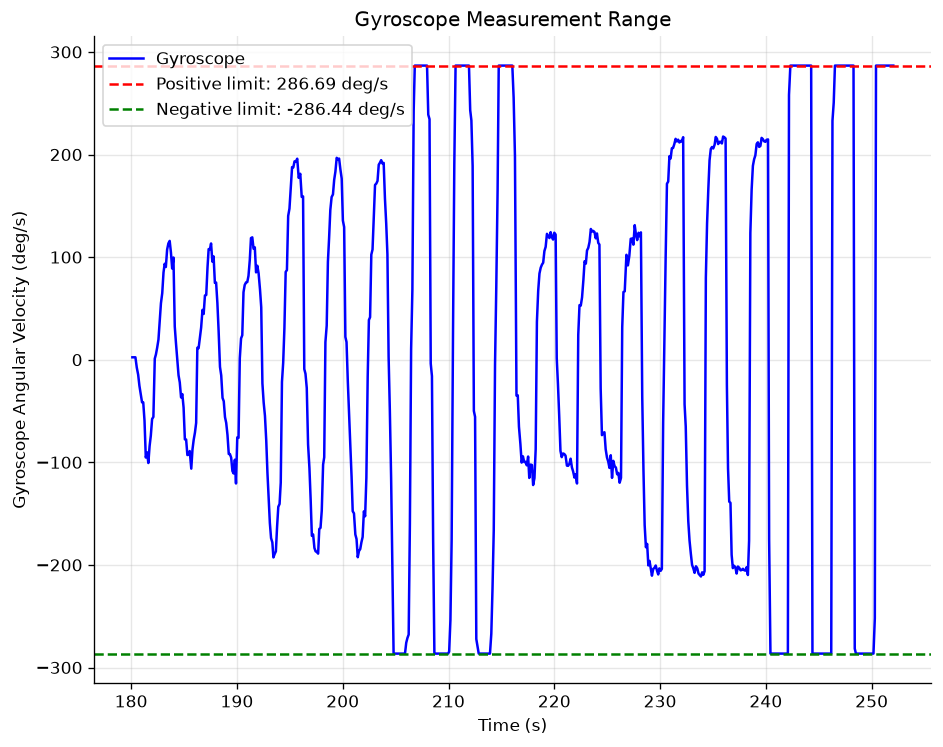

Positive limit: 286.69 deg/s
Negative limit: -286.44 deg/s


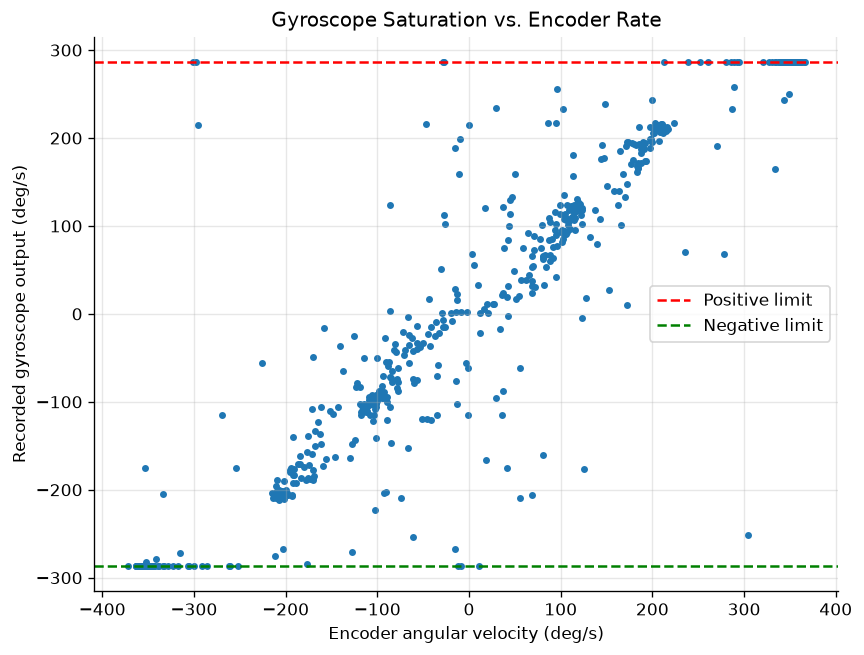

In [17]:
moving_phase = data[data['phase'].isin(['sin', 'rect'])]

gz = moving_phase['gz_mdeg_s'] / 1000

positive_limit = gz.max()
negative_limit = gz.min()

plt.figure(figsize=(9, 7))

plt.plot(
    moving_phase['t'],
    gz,
    'b-',
    label='Gyroscope'
)

plt.axhline(
    positive_limit,
    color='red',
    linestyle='--',
    label=f'Positive limit: {positive_limit:.2f} deg/s'
)

plt.axhline(
    negative_limit,
    color='green',
    linestyle='--',
    label=f'Negative limit: {negative_limit:.2f} deg/s'
)

plt.xlabel('Time (s)')
plt.ylabel('Gyroscope Angular Velocity (deg/s)')
plt.title('Gyroscope Measurement Range')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print(f"Positive limit: {positive_limit:.2f} deg/s")
print(f"Negative limit: {negative_limit:.2f} deg/s")

PARAMS['wmax'] = (positive_limit-negative_limit)/2

# Compare gyro output with encoder rate
range_heading = RADIUS / BASE * (data['encR_deg'] - data['encL_deg'])
range_rate = np.gradient(range_heading, data['t'])
range_mask = data['phase'].isin(['sin', 'rect']).to_numpy()

plt.figure(figsize=(8, 6))
plt.scatter(range_rate[range_mask], data['gz'].to_numpy()[range_mask], s=10)
plt.axhline(positive_limit, color='red', linestyle='--', label='Positive limit')
plt.axhline(negative_limit, color='green', linestyle='--', label='Negative limit')
plt.xlabel('Encoder angular velocity (deg/s)')
plt.ylabel('Recorded gyroscope output (deg/s)')
plt.title('Gyroscope Saturation vs. Encoder Rate')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 1.4 Resolution

In [18]:
raw_values = np.sort(static['gz_mdeg_s'].unique())

differences = np.diff(raw_values)

resolution_mdeg_s = differences[differences > 0].min()

resolution_deg_s = resolution_mdeg_s / 1000

print(f"Gyroscope resolution: {resolution_deg_s:.6f} deg/s")

PARAMS['resolution'] = resolution_deg_s

Gyroscope resolution: 0.008000 deg/s


### 1.5 Noise

Mean noise:       -0.012643 deg/s
Standard deviation: 0.074899 deg/s
Measurement noise R: 0.00560981 (deg/s)^2
Normality p-value: 0.260886
Samples outside 3 sigma: 5 of 1534


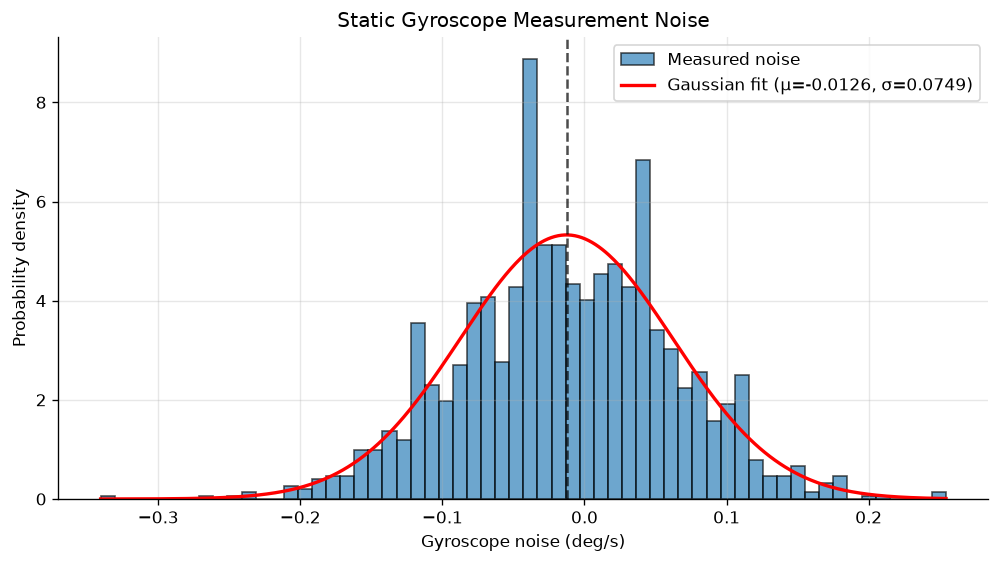

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, normaltest, skew, kurtosis

# Remove initial bias
noise = static['gz_mdeg_s'].dropna().to_numpy() / 1000 - PARAMS['b0']

# Statistics
mu = np.mean(noise)
sigma = np.std(noise, ddof=1)
R = sigma**2

# Estimate sample rate from real timestamps
dt = np.diff(np.sort(static['t'].dropna().unique()))

# Gaussianity test
statistic, p_value = normaltest(noise)

# Outlier detection: 3-sigma rule
outliers = np.abs(noise - mu) > 3 * sigma

print(f"Mean noise:       {mu:.6f} deg/s")
print(f"Standard deviation: {sigma:.6f} deg/s")
print(f"Measurement noise R: {R:.8f} (deg/s)^2")
print(f"Normality p-value: {p_value:.6g}")
print(f"Samples outside 3 sigma: {outliers.sum()} of {len(noise)}")

# Histogram and fitted Gaussian
x = np.linspace(noise.min(), noise.max(), 500)

plt.figure(figsize=(10, 5))

plt.hist(
    noise,
    bins=60,
    density=True,
    alpha=0.65,
    edgecolor='black',
    label='Measured noise'
)

plt.plot(
    x,
    norm.pdf(x, mu, sigma),
    'r-',
    linewidth=2,
    label=f'Gaussian fit (μ={mu:.4f}, σ={sigma:.4f})'
)

plt.axvline(mu, color='black', linestyle='--', alpha=0.7)

plt.xlabel('Gyroscope noise (deg/s)')
plt.ylabel('Probability density')
plt.title('Static Gyroscope Measurement Noise')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

PARAMS['noise_mean'] = mu
PARAMS['noise_std'] = sigma

### 1.6 Scale factor

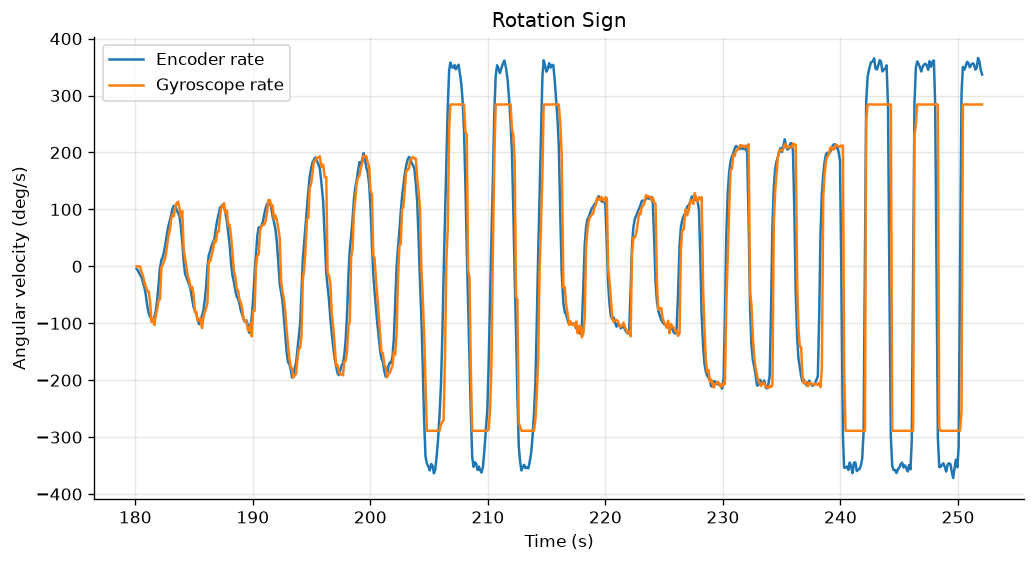

Matching signs: 93.90% of rotation samples
Positive gyroscope rate matches increasing encoder heading (CCW).


In [20]:
rotation = data[data['phase'].isin(['sin', 'rect'])].copy()

t = rotation['t'].to_numpy()
gz_raw = rotation['gz_mdeg_s'].to_numpy()
gz_corrected = gz_raw / 1000 - PARAMS['b0']

theta_enc = RADIUS / BASE * (
    rotation['encR_deg'] - rotation['encL_deg']
).to_numpy()
theta_gyro = cumulative_trapezoid(gz_corrected, t, initial=0)
omega_enc = np.gradient(theta_enc, t)

plt.figure(figsize=(10, 5))
plt.plot(t, omega_enc, label='Encoder rate')
plt.plot(t, gz_corrected, label='Gyroscope rate')
plt.xlabel('Time (s)')
plt.ylabel('Angular velocity (deg/s)')
plt.title('Rotation Sign')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

same_sign = omega_enc * gz_corrected > 0
print(f"Matching signs: {same_sign.mean()*100:.2f}% of rotation samples")
print('Positive gyroscope rate matches increasing encoder heading (CCW).')
PARAMS['rotation_sign'] = 1

The conversion is 0.001 because the logged readings are in mdeg/s. Both axes use the same readings, so this plot checks the unit conversion.

Split each phase and amplitude into segments with one measured encoder direction. Fit each segment with at least three samples, then average the scale errors by direction and amplitude. Use unclipped turns for the scale-factor estimate; keep clipped turns in the speed comparison.

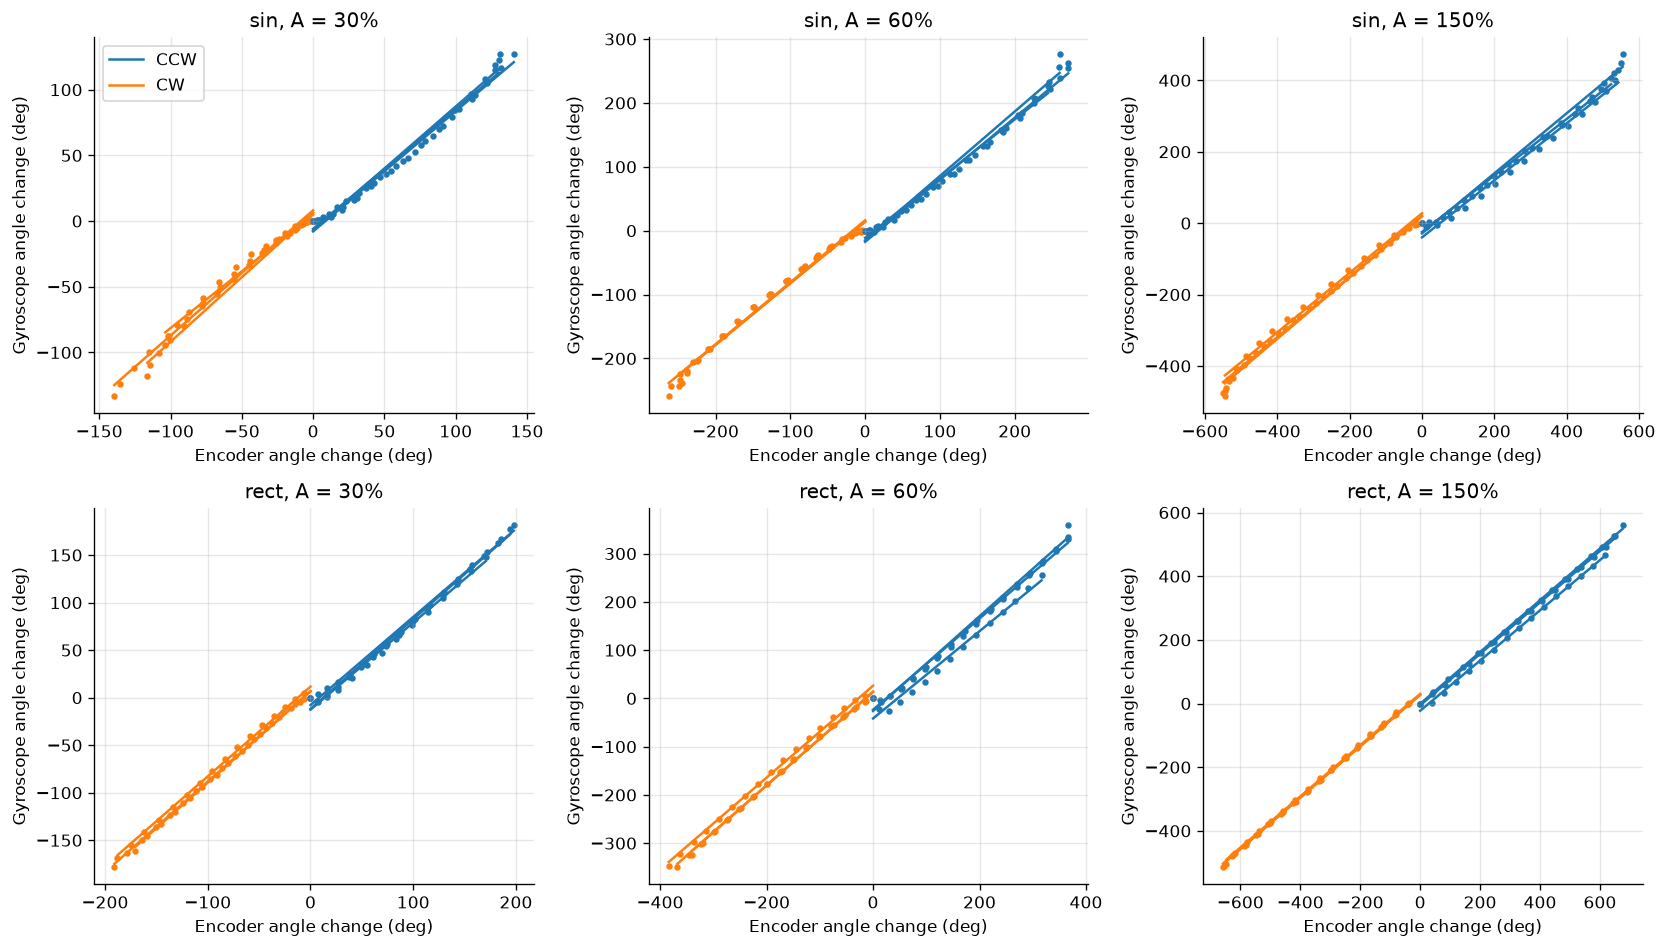

Scale-factor error (%)


direction          CCW     CW
phase amplitude              
rect  30         -7.08  -4.84
      60         -5.63  -3.67
      150       -19.64 -19.42
sin   30         -7.65  -6.59
      60         -3.12  -3.43
      150       -18.95 -15.42

CCW scale-factor error (unclipped turns): -5.87%
CW scale-factor error (unclipped turns): -4.63%


In [22]:
rotation['theta_enc'] = theta_enc
rotation['theta_gyro'] = theta_gyro

positive_limit = rotation['gz'].max()
negative_limit = rotation['gz'].min()

scale_results = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for row, (phase, start) in enumerate([('sin', 180), ('rect', 216)]):
    phase_data = rotation[rotation['phase'] == phase].copy()
    stage = np.minimum(((phase_data['t'] - start) // 12).astype(int), 2)
    phase_data['amplitude'] = np.array([30, 60, 150])[stage]
    direction = np.sign(phase_data['theta_enc'].diff())
    direction = direction.replace(0, np.nan).ffill().bfill()
    new_turn = ((direction != direction.shift()) |
                (phase_data['amplitude'] != phase_data['amplitude'].shift()))
    phase_data['turn'] = new_turn.cumsum()

    for turn, turn_data in phase_data.groupby('turn'):
        if len(turn_data) < 3:
            continue
        amplitude = int(turn_data['amplitude'].iloc[0])
        x = turn_data['theta_enc'].to_numpy()
        y = turn_data['theta_gyro'].to_numpy()
        x = x - x[0]
        y = y - y[0]

        if np.ptp(x) == 0:
            continue
        direction = 'CCW' if x[-1] > 0 else 'CW'
        coeffs = np.polyfit(x, y, 1)
        poly = np.poly1d(coeffs)
        s = coeffs[0] - 1

        clipped = (
            (turn_data['gz'] >= positive_limit - PARAMS['resolution']) |
            (turn_data['gz'] <= negative_limit + PARAMS['resolution'])
        ).any()

        scale_results.append({
            'phase': phase,
            'amplitude': amplitude,
            'direction': direction,
            's_percent': s * 100,
            'clipped': clipped
        })

        ax = axes[row, [30, 60, 150].index(amplitude)]
        color = 'tab:blue' if direction == 'CCW' else 'tab:orange'
        ax.scatter(x, y, s=8, color=color)
        order = np.argsort(x)
        ax.plot(x[order], poly(x[order]), color=color)
        ax.set_title(f'{phase}, A = {amplitude}%')
        ax.set_xlabel('Encoder angle change (deg)')
        ax.set_ylabel('Gyroscope angle change (deg)')
        ax.grid(alpha=0.3)

axes[0, 0].plot([], [], color='tab:blue', label='CCW')
axes[0, 0].plot([], [], color='tab:orange', label='CW')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

scale_results = pd.DataFrame(scale_results)
scale_by_amplitude = scale_results.groupby(
    ['phase', 'amplitude', 'direction']
)['s_percent'].mean().unstack('direction')

print('Scale-factor error (%)')
display(scale_by_amplitude.round(2))

unclipped = scale_results[~scale_results['clipped']]
scale_by_direction = unclipped.groupby('direction')['s_percent'].mean()

for direction in ['CCW', 'CW']:
    s = scale_by_direction[direction]
    print(f"{direction} scale-factor error (unclipped turns): {s:.2f}%")
    PARAMS[f'scale_error_{direction.lower()}'] = s / 100

The unclipped fits give an apparent negative scale error in both directions. The error is not identical across speeds or signals; reversal timing and encoder geometry affect these angle fits. At A = 150% (clipped to 100% motor power), the gyro saturates and the apparent error becomes larger. These fastest turns cannot give an unclipped scale factor.


## 2. Compare gyroscope and encoder heading

$$
\theta_{gyro}(t) = \int (\omega_z - b_0)\,dt,
\qquad
\theta_{enc}(t) = \frac{r}{L}(\varphi_R - \varphi_L).
$$

Both headings start at zero and stay unwrapped. Encoder angles are in degrees, so both headings are in degrees. Subtract the initial gyro bias only, as required by the lab.

In [23]:
t = data['t'].to_numpy()
gz_corrected = data['gz'].to_numpy() - PARAMS['b0']

theta_gyro = cumulative_trapezoid(gz_corrected, t, initial=0)
theta_enc = RADIUS / BASE * (
    data['encR_deg'] - data['encL_deg']
).to_numpy()
theta_enc = theta_enc - theta_enc[0]

error = theta_gyro - theta_enc
omega_enc = np.gradient(theta_enc, t)

### 2.1 Heading and error

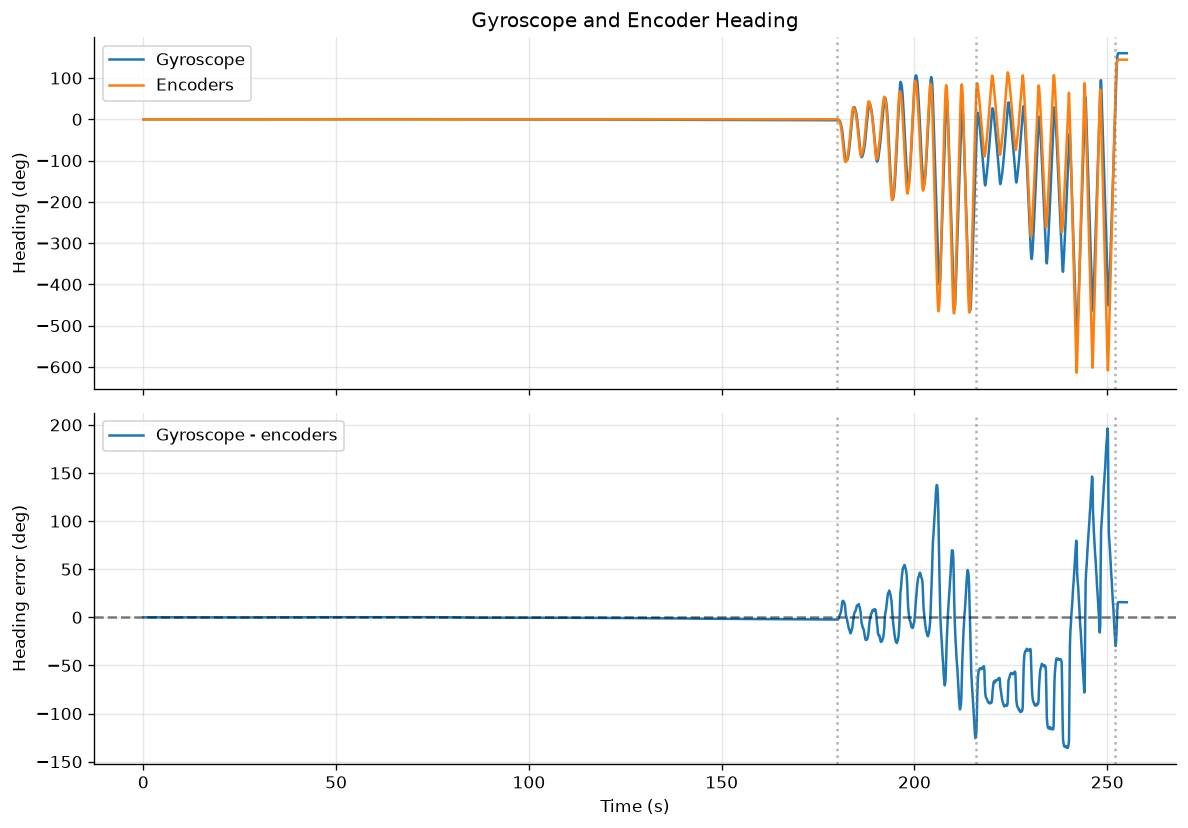

Error at end of static phase: -2.29 deg
Final gyro heading: 160.11 deg
Final encoder heading: 144.40 deg
Final heading error: 15.70 deg


In [24]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(t, theta_gyro, label='Gyroscope')
axes[0].plot(t, theta_enc, label='Encoders')
axes[0].set_ylabel('Heading (deg)')
axes[0].set_title('Gyroscope and Encoder Heading')
axes[0].legend()

axes[1].plot(t, error, label='Gyroscope - encoders')
axes[1].axhline(0, color='black', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Heading error (deg)')
axes[1].legend()

for ax in axes:
    for boundary in [180, 216, 252]:
        ax.axvline(boundary, color='grey', linestyle=':', alpha=0.6)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

static_mask = data['phase'].eq('static').to_numpy()
print(f"Error at end of static phase: {error[static_mask][-1]:.2f} deg")
print(f"Final gyro heading: {theta_gyro[-1]:.2f} deg")
print(f"Final encoder heading: {theta_enc[-1]:.2f} deg")
print(f"Final heading error: {error[-1]:.2f} deg")

### 2.2 Angular velocity

Compare the bias-corrected gyro rate with the derivative of encoder heading. The shaded intervals use A = 150%, clipped to 100% motor power.

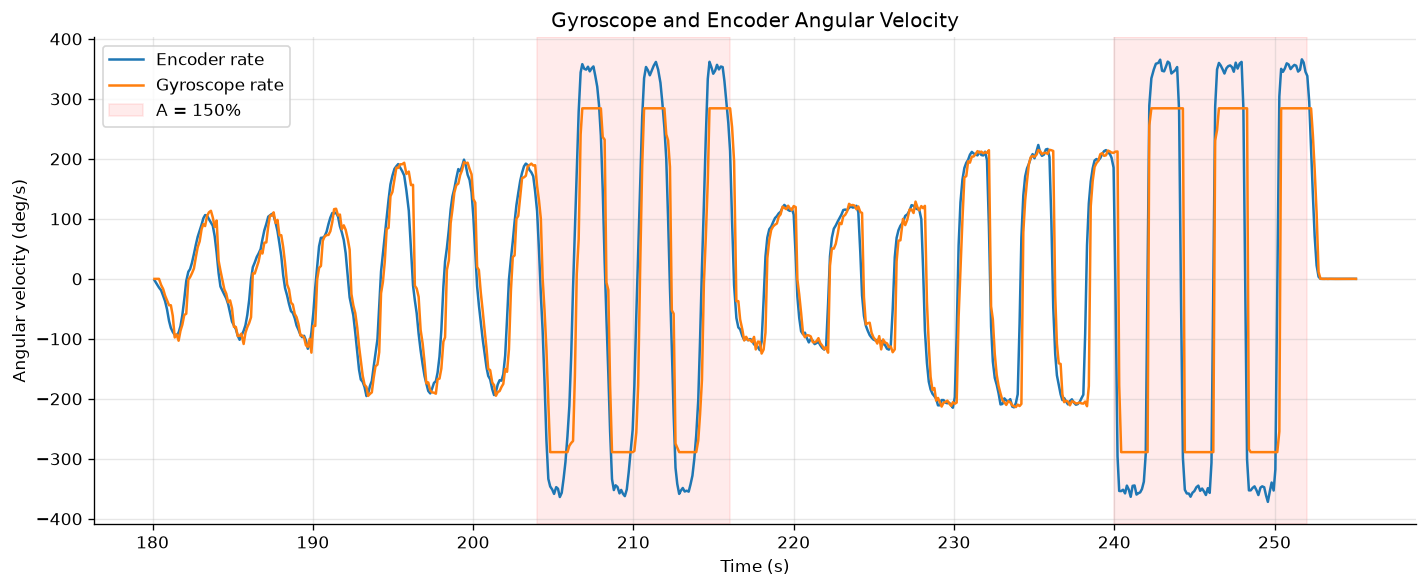

In [25]:
moving_mask = data['phase'].isin(['sin', 'rect', 'rest']).to_numpy()

plt.figure(figsize=(12, 5))
plt.plot(t[moving_mask], omega_enc[moving_mask], label='Encoder rate')
plt.plot(t[moving_mask], gz_corrected[moving_mask], label='Gyroscope rate')

for start, end in [(204, 216), (240, 252)]:
    plt.axvspan(start, end, color='red', alpha=0.08,
                label='A = 150%' if start == 204 else None)

plt.xlabel('Time (s)')
plt.ylabel('Angular velocity (deg/s)')
plt.title('Gyroscope and Encoder Angular Velocity')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 2.3 Gyroscope angle against encoder angle

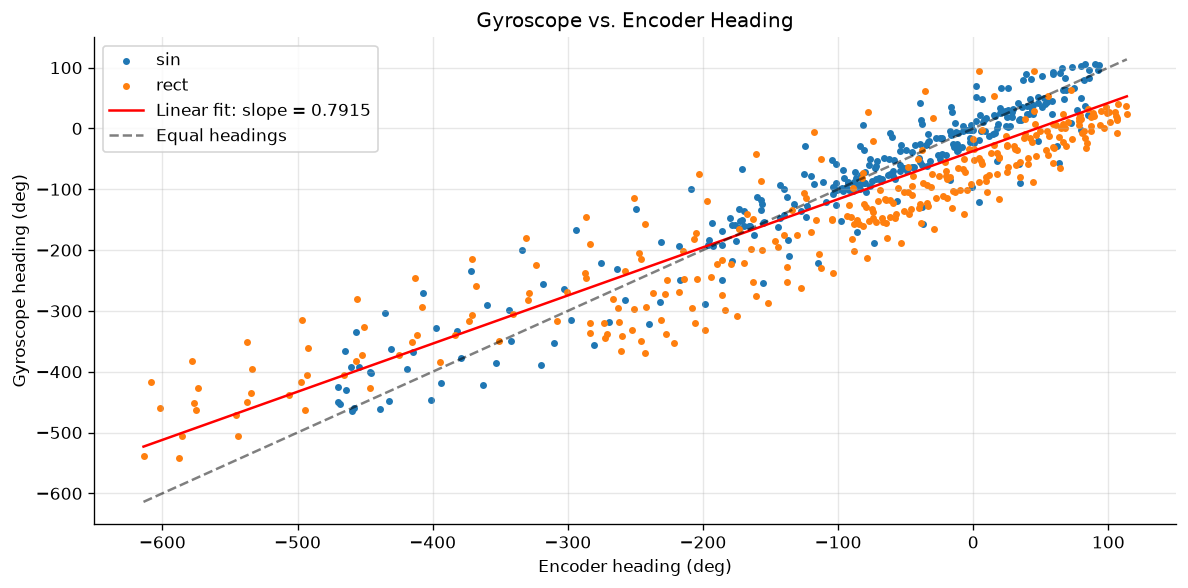

Slope (1 + s): 0.7915
Apparent scale-factor error over all turns: -20.85%


In [26]:
rotation_mask = data['phase'].isin(['sin', 'rect']).to_numpy()
x = theta_enc[rotation_mask]
y = theta_gyro[rotation_mask]

coeffs = np.polyfit(x, y, 1)
poly = np.poly1d(coeffs)
x_fit = np.linspace(x.min(), x.max(), 200)

plt.figure(figsize=(10, 5))

for phase in ['sin', 'rect']:
    mask = data['phase'].eq(phase).to_numpy()
    plt.scatter(theta_enc[mask], theta_gyro[mask], s=10, label=phase)

plt.plot(x_fit, poly(x_fit), 'r-',
         label=f'Linear fit: slope = {coeffs[0]:.4f}')
plt.plot(x_fit, x_fit, 'k--', alpha=0.5, label='Equal headings')
plt.xlabel('Encoder heading (deg)')
plt.ylabel('Gyroscope heading (deg)')
plt.title('Gyroscope vs. Encoder Heading')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Slope (1 + s): {coeffs[0]:.4f}")
print(f"Apparent scale-factor error over all turns: {(coeffs[0]-1)*100:.2f}%")

### 2.4 Error sources

The bias-corrected heading drifts by -2.29° during the 3-min static phase while the encoders stay at zero. This is the residual gyro drift after subtracting the initial bias.

During rotation, the gyro generally measures less rotation than the encoders. Section 1.6 gives apparent scale errors of -5.87% CCW and -4.63% CW for unclipped segments with one measured encoder direction. The error changes with each turn and can partly cancel when the direction reverses.

The largest differences occur in the fast rotation stages, at 204–216 s and 240–252 s. The gyro rate flattens near ±286.6 deg/s while the encoder rate continues beyond it. Saturation adds heading error in these intervals. The overall angle-fit slope is 0.7915, but this includes saturation and accumulated drift; use the separate unclipped CW/CCW fits from section 1.6 for the scale factor.

At reversals, the rate curves also differ during acceleration. Wheel slip may affect the encoder reference, but this log alone cannot separate slip from gyro response and sampling effects. No floor-mark measurement is available to check which heading is closer to the real rotation.

The robot coasts after the motors stop at 252 s, so the early `rest` samples still contain rotation. Once both encoder readings stop changing, the error is nearly constant. At the end, the gyro heading is 160.11°, the encoder heading is 144.40°, and their difference is 15.70°. The small final difference does not describe the larger errors during the turns.

## 3. Simulated gyroscope

Use the identified offset, drift, direction-dependent gain, noise, saturation and resolution:

$$
\omega_{sim}(t_k) = Q_\Delta\left(\operatorname{sat}_{\pm\omega_{max}}
\left[(1+s)\omega_{true}(t_k) + b_0 + d t_k + n_k\right]\right).
$$

Rates are in deg/s, time is in seconds and drift is in deg/s². The input is the recorded encoder rate. It is a reference estimate, so this overlay is a consistency check rather than an independent validation of the gyro model.

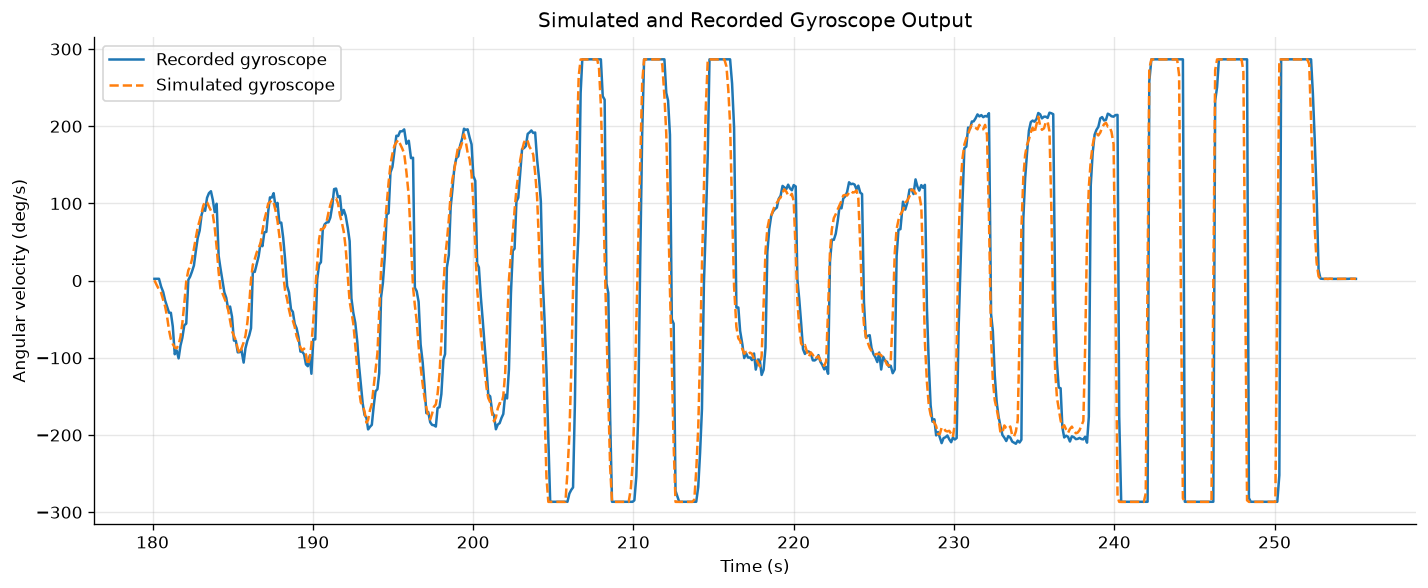

Rotation and rest rate RMSE: 72.60 deg/s


In [27]:
rng = np.random.default_rng(0)


def gyro_sim(omega_true, t):
    omega_true = np.asarray(omega_true)
    t = np.asarray(t)
    s = np.where(omega_true >= 0,
                 PARAMS['scale_error_ccw'], PARAMS['scale_error_cw'])
    noise = rng.normal(0, PARAMS['noise_std'], size=omega_true.shape)
    measured = ((1 + s) * omega_true + PARAMS['calibrated_b0']
                + PARAMS['drift_rate'] * t + noise)
    measured = np.clip(measured, -PARAMS['wmax'], PARAMS['wmax'])
    return np.round(measured / PARAMS['resolution']) * PARAMS['resolution']


t = data['t'].to_numpy()
theta_enc = RADIUS / BASE * (
    data['encR_deg'] - data['encL_deg']
).to_numpy()
omega_enc = np.gradient(theta_enc, t)
simulated_rate = gyro_sim(omega_enc, t)

mask = data['phase'].isin(['sin', 'rect', 'rest']).to_numpy()
plt.figure(figsize=(12, 5))
plt.plot(t[mask], data['gz'].to_numpy()[mask], label='Recorded gyroscope')
plt.plot(t[mask], simulated_rate[mask], '--', label='Simulated gyroscope')
plt.xlabel('Time (s)')
plt.ylabel('Angular velocity (deg/s)')
plt.title('Simulated and Recorded Gyroscope Output')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

model_rmse = np.sqrt(np.mean(
    (simulated_rate[mask] - data['gz'].to_numpy()[mask])**2
))
print(f"Rotation and rest rate RMSE: {model_rmse:.2f} deg/s")

The model reproduces the rate limits and rotation direction. It does not model the timing differences at reversals. The angle-based gain estimates also include encoder geometry and sampling effects, so the model need not match every instantaneous rate.

## 4. Parameter table

All values below come from `data/lab9_gyro.csv`, an unchanged copy of `gyro_encoder_compare.csv`. The baseline offset is used in chapters 1–2; the own-calibration offset is used in chapter 3.

In [30]:
static_t = static['t'].to_numpy()
raw_heading = cumulative_trapezoid(static['gz'], static_t, initial=0)
heading_drift = np.polyfit(static_t, raw_heading, 1)[0] * 60

rows = [
    ['Offset (baseline)', 'b0', PARAMS['b0'], 'deg/s', 'First 30 s mean'],
    ['Offset (own calibration)', 'b0', PARAMS['calibrated_b0'], 'deg/s',
     'First 30 s mean after 3-sigma rejection'],
    ['Bias drift', 'd', PARAMS['drift_rate'] * 60, 'deg/s/min',
     'Line through 30-s window means'],
    ['Heading drift, uncorrected', '', heading_drift, 'deg/min',
     'Line through integrated static rate'],
    ['Lower measurement limit', '-omega_max', rotation['gz'].min(), 'deg/s',
     'Minimum rotation reading'],
    ['Upper measurement limit', '+omega_max', rotation['gz'].max(), 'deg/s',
     'Maximum rotation reading'],
    ['Resolution', 'Delta', PARAMS['resolution'], 'deg/s',
     'Smallest nonzero spacing in static readings'],
    ['Noise standard deviation', 'sigma', PARAMS['noise_std'], 'deg/s',
     '3-min static log, initial bias subtracted'],
    ['Measurement noise variance', 'R', PARAMS['noise_std']**2, '(deg/s)^2',
     'Static rate variance'],
    ['Scale-factor error CCW', 's', PARAMS['scale_error_ccw'] * 100, '%',
     'Mean angle-fit error in unclipped CCW turns'],
    ['Scale-factor error CW', 's', PARAMS['scale_error_cw'] * 100, '%',
     'Mean angle-fit error in unclipped CW turns'],
    ['Positive rotation direction', '', 'CCW', '', 'Gyro and encoder rate signs']
]
parameters = pd.DataFrame(rows, columns=['parameter', 'symbol', 'value', 'unit', 'method'])

display(parameters)
parameters.to_csv(OUTPUT_DIR / 'parameters.csv', index=False)

comparison = pd.DataFrame({
    't_s': data['t'], 'phase': data['phase'],
    'gyro_heading_deg': cumulative_trapezoid(
        data['gz'].to_numpy() - PARAMS['b0'], data['t'], initial=0
    ),
    'encoder_heading_deg': theta_enc - theta_enc[0],
    'recorded_rate_deg_s': data['gz'],
    'encoder_rate_deg_s': omega_enc,
    'simulated_rate_deg_s': simulated_rate
})
comparison['heading_error_deg'] = (
    comparison['gyro_heading_deg'] - comparison['encoder_heading_deg']
)
comparison.to_csv(OUTPUT_DIR / 'heading_comparison.csv', index=False)
scale_results.to_csv(OUTPUT_DIR / 'turns.csv', index=False)

results = {
    'source': 'data/lab9_gyro.csv',
    'sha256': hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
    'samples': len(data),
    'median_interval_s': float(np.median(np.diff(data['t']))),
    'parameters': dict(PARAMS),
    'wheel_radius_m': RADIUS,
    'wheel_separation_m': BASE,
    'static_calibrated_final_deg': float(static_heading[-1]),
    'rotation_calibrated_final_error_deg': float(calibrated_error[-1]),
    'final_gyro_heading_deg': float(comparison['gyro_heading_deg'].iloc[-1]),
    'final_encoder_heading_deg': float(comparison['encoder_heading_deg'].iloc[-1]),
    'final_heading_error_deg': float(comparison['heading_error_deg'].iloc[-1]),
    'model_rate_rmse_deg_s': float(model_rmse),
    'floor_mark_slip_angle_deg': None
}
(OUTPUT_DIR / 'results.json').write_text(json.dumps(results, indent=2) + '\n')

,parameter,symbol,value,unit,method
0,Offset (baseline),b0,2.413529,deg/s,First 30 s mean
1,Offset (own calibration),b0,2.412535,deg/s,First 30 s mean after 3-sigma rejection
2,Bias drift,d,-0.013668,deg/s/min,Line through 30-s window means
3,"Heading drift, uncorrected",,144.048943,deg/min,Line through integrated static rate
4,Lower measurement limit,-omega_max,-286.44,deg/s,Minimum rotation reading
5,Upper measurement limit,+omega_max,286.685,deg/s,Maximum rotation reading
6,Resolution,Delta,0.008,deg/s,Smallest nonzero spacing in static readings
7,Noise standard deviation,sigma,0.074899,deg/s,"3-min static log, initial bias subtracted"
8,Measurement noise variance,R,0.00561,(deg/s)^2,Static rate variance
9,Scale-factor error CCW,s,-5.868987,%,Mean angle-fit error in unclipped CCW turns


998

## 5. Short analysis

Without offset calibration, the measured bias of 2.4135 deg/s contributes about 24.1° after 10 s, 144.8° after 1 min and 434.4° after 3 min. This dominates the stationary heading error.

`calibrate_gyro(log)` uses the first 30 s of the static log. It rejects readings farther than three standard deviations from the median and averages the rest. The bias plot is nearly flat from 10–30 s, so 30 s gives a settled estimate with more samples. It removes one spike and returns 2.412535 deg/s. The residual stationary heading error at the end of the 3-min log is -2.11°.

After calibration, scale error and saturation dominate the differences during the recorded turns. The unclipped angle fits give apparent errors of -5.87% CCW and -4.63% CW; sampling and geometry affect these estimates (random errors). At the highest speed, the encoder rate reaches about ±350 deg/s while the gyro clips near ±286.6 deg/s. Reversals can partly cancel accumulated error, so total elapsed time alone does not determine the driving error.

Using the measured drift and sampling interval, the linear-drift model contributes approximately -0.01°, -0.41° and -3.69° after 10 s, 1 min and 3 min. Independent white noise with the measured standard deviation would contribute about 0.08°, 0.20° and 0.34° RMS at those times. Thus drift overtakes white noise over longer stationary intervals; during repeated fast turns, scale error and saturation are larger. These are model estimates, not measurements of 3 min of driving.
